# Disease Risk Prediction Using Explainable AI
### Predicting Heart-Disease Risk with Classical Machine Learning

**Course:** Machine Learning — Mini Project  
**Topic #5 (Healthcare & Social Impact):** Disease Risk Prediction Using Explainable AI  
**Constraint honoured:** *No deep learning.* Every model used here is a classical algorithm from the standard ML syllabus (regression, decision trees, ensembles, SVM, kNN, Naive Bayes, PCA, K-Means).

---

## 1. Problem Statement & Objectives

Heart disease is one of the leading causes of death worldwide. Clinicians collect simple, inexpensive
measurements (age, blood pressure, cholesterol, ECG results, ...), but manually combining many factors
into a risk estimate is hard. **Can a machine-learning model predict whether a patient is at risk of
heart disease from routine clinical measurements — and explain *why* it made each prediction?**

**Objectives**
1. Collect a real, publicly available clinical dataset (UCI Cleveland Heart Disease).
2. Perform preprocessing (missing-value handling, encoding, scaling) and exploratory data analysis.
3. Train and compare **six classical ML algorithms**: Logistic Regression, Decision Tree, Random Forest, SVM (RBF), k-Nearest Neighbours, Gaussian Naive Bayes.
4. Evaluate with Accuracy, Precision, Recall, F1 and ROC-AUC + 5-fold cross-validation; tune hyperparameters with grid search.
5. Make the model **explainable**: logistic-regression odds ratios, tree feature importance, permutation importance, human-readable decision rules, and per-patient explanations.
6. Deliver a small **working prototype** (in-notebook interactive risk checker) and save all results/figures.



## 2. Dataset

**Source:** UCI Machine Learning Repository — *Heart Disease (Cleveland)*, processed subset.  
Original URL: <https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data>  
Local copy: `data/heart_disease.csv` (303 patients, 13 features + binary target).

The original target `num` (0–4 angiographic disease severity) is binarised: **0 = no disease, 1 = disease present** (any severity 1–4).

| Feature | Meaning |
|---|---|
| `age` | Age in years |
| `sex` | 1 = male, 0 = female |
| `cp` | Chest-pain type: 1 typical angina, 2 atypical angina, 3 non-anginal pain, 4 asymptomatic |
| `trestbps` | Resting blood pressure (mm Hg) |
| `chol` | Serum cholesterol (mg/dl) |
| `fbs` | Fasting blood sugar > 120 mg/dl (1 = true, 0 = false) |
| `restecg` | Resting ECG: 0 normal, 1 ST-T abnormality, 2 left-ventricular hypertrophy |
| `thalach` | Maximum heart rate achieved |
| `exang` | Exercise-induced angina (1 = yes, 0 = no) |
| `oldpeak` | ST depression induced by exercise relative to rest |
| `slope` | Slope of peak-exercise ST segment: 1 upsloping, 2 flat, 3 downsloping |
| `ca` | Number of major vessels (0–3) coloured by fluoroscopy |
| `thal` | Thalassemia / stress-test result: 3 normal, 6 fixed defect, 7 reversable defect |
| `target` | **0 = no heart disease, 1 = heart disease** |


## 3. Setup & Data Loading

In [1]:
%matplotlib inline
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     GridSearchCV)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, silhouette_score)
from sklearn.inspection import permutation_importance
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import joblib

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
FIG_DIR = "results/figures"
os.makedirs(FIG_DIR, exist_ok=True)

df = pd.read_csv("data/heart_disease.csv")
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## 4. Exploratory Data Analysis (EDA)

First: structure, data types, missing values and class balance.

In [2]:
print("Data types:\n", df.dtypes, "\n")
print("Missing values per column:\n", df.isna().sum(), "\n")
print("Class balance (0 = healthy, 1 = disease):")
print(df["target"].value_counts())
df.describe().round(2)

Data types:
 age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object 

Missing values per column:
 age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64 

Class balance (0 = healthy, 1 = disease):
target
0    164
1    139
Name: count, dtype: int64


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,299.00,301.00,303.00
mean,54.44,0.68,3.16,131.69,246.69,0.15,0.99,149.61,0.33,1.04,1.60,0.67,4.73,0.46
std,9.04,0.47,0.96,17.60,51.78,0.36,0.99,22.88,0.47,1.16,0.62,0.94,1.94,0.50
min,29.00,0.00,1.00,94.00,126.00,0.00,0.00,71.00,0.00,0.00,1.00,0.00,3.00,0.00
25%,48.00,0.00,3.00,120.00,211.00,0.00,0.00,133.50,0.00,0.00,1.00,0.00,3.00,0.00
50%,56.00,1.00,3.00,130.00,241.00,0.00,1.00,153.00,0.00,0.80,2.00,0.00,3.00,0.00
75%,61.00,1.00,4.00,140.00,275.00,0.00,2.00,166.00,1.00,1.60,2.00,1.00,7.00,1.00
max,77.00,1.00,4.00,200.00,564.00,1.00,2.00,202.00,1.00,6.20,3.00,3.00,7.00,1.00


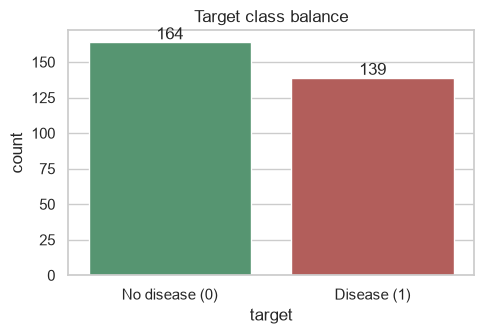

In [3]:
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(x="target", data=df, hue="target", palette=["#4c9f70", "#c0504d"], legend=False, ax=ax)
ax.set_xticks([0, 1]); ax.set_xticklabels(["No disease (0)", "Disease (1)"])
ax.set_title("Target class balance")
for i, v in enumerate(df["target"].value_counts().sort_index()):
    ax.text(i, v + 2, str(v), ha="center")
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/eda_target_balance.png", dpi=150); plt.show()

### 4.1 Distributions of the numeric features

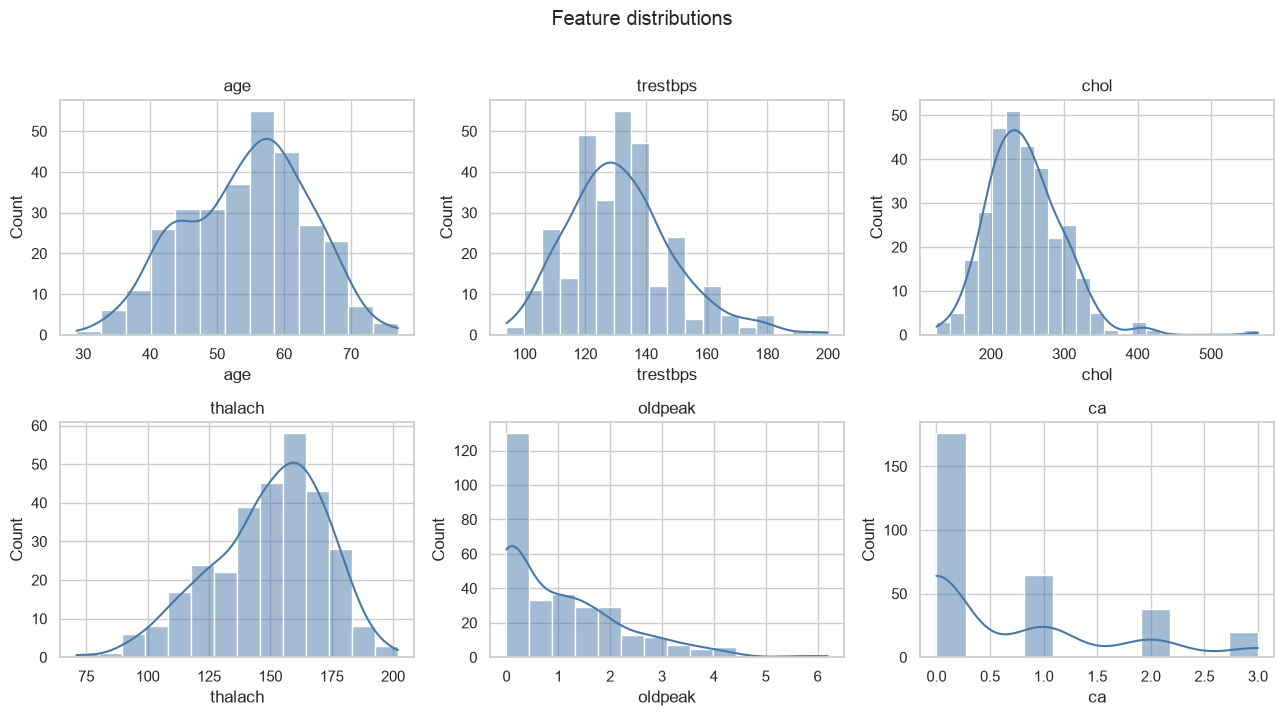

In [4]:
num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col].dropna(), kde=True, ax=ax, color="#4878a8")
    ax.set_title(col)
fig.suptitle("Feature distributions", y=1.02)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/eda_distributions.png", dpi=150, bbox_inches="tight"); plt.show()

### 4.2 Correlation heatmap (which features move together / with the target?)

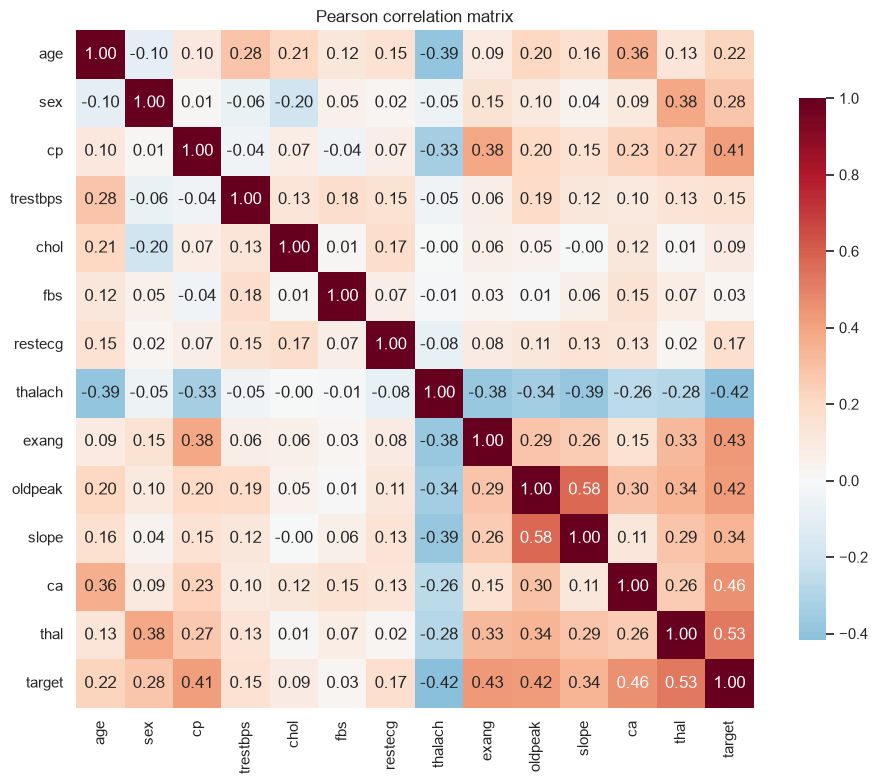

Correlation with target (sorted):
thal        0.526
ca          0.460
exang       0.432
oldpeak     0.425
cp          0.414
slope       0.339
sex         0.277
age         0.223
restecg     0.169
trestbps    0.151
chol        0.085
fbs         0.025
thalach    -0.417
Name: target, dtype: float64


In [5]:
fig, ax = plt.subplots(figsize=(10, 8))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax,
            square=True, cbar_kws={"shrink": .8})
ax.set_title("Pearson correlation matrix")
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/eda_correlation.png", dpi=150); plt.show()
print("Correlation with target (sorted):")
print(corr["target"].drop("target").sort_values(ascending=False).round(3))

### 4.3 How do key features relate to disease?

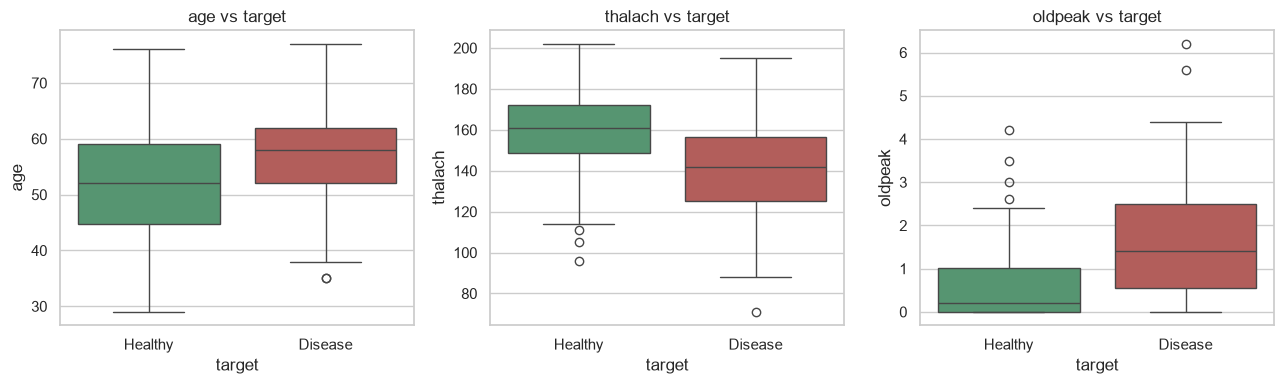

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, ["age", "thalach", "oldpeak"]):
    sns.boxplot(x="target", y=col, data=df, hue="target",
                palette=["#4c9f70", "#c0504d"], legend=False, ax=ax)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Healthy", "Disease"])
    ax.set_title(f"{col} vs target")
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/eda_boxplots.png", dpi=150); plt.show()

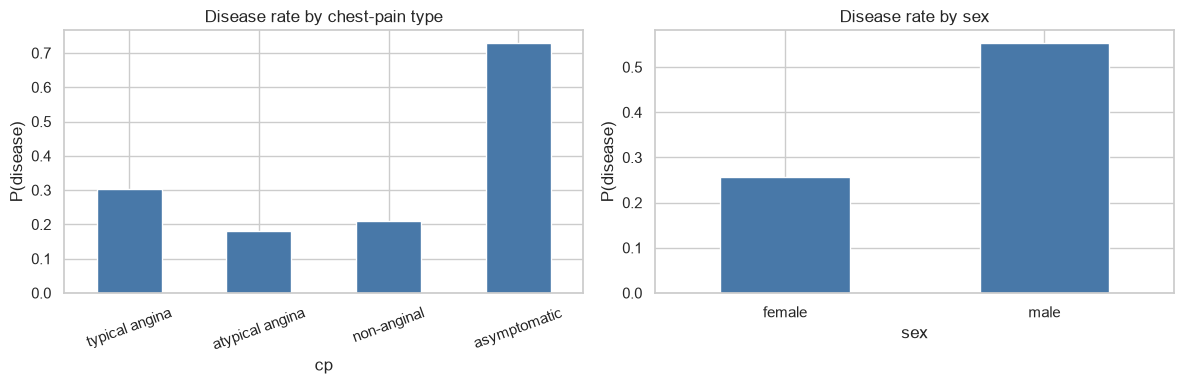

Disease rate by chest-pain type:
 cp
typical angina     0.304
atypical angina    0.180
non-anginal        0.209
asymptomatic       0.729
Name: target, dtype: float64

Disease rate by sex:
 sex
female    0.258
male      0.553
Name: target, dtype: float64

Male patients: 68.0%


In [7]:
# Disease rate by chest-pain type and by sex
cp_labels = {1: "typical angina", 2: "atypical angina", 3: "non-anginal", 4: "asymptomatic"}
rate_cp = df.groupby("cp")["target"].mean().rename(index=cp_labels)
rate_sex = df.groupby("sex")["target"].mean().rename(index={0: "female", 1: "male"})

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
rate_cp.plot(kind="bar", ax=axes[0], color="#4878a8", rot=20)
axes[0].set_title("Disease rate by chest-pain type"); axes[0].set_ylabel("P(disease)")
rate_sex.plot(kind="bar", ax=axes[1], color="#4878a8", rot=0)
axes[1].set_title("Disease rate by sex"); axes[1].set_ylabel("P(disease)")
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/eda_disease_rates.png", dpi=150); plt.show()

print("Disease rate by chest-pain type:\n", rate_cp.round(3))
print("\nDisease rate by sex:\n", rate_sex.round(3))
print("\nMale patients: %.1f%%" % (100 * df['sex'].mean()))

**EDA observations** *(filled from the outputs above)*:
- The dataset is small (303 patients) but reasonably balanced, so accuracy is a meaningful metric.
- Only `ca` (4 values) and `thal` (2 values) have missing entries — handled by imputation below.
- Patients who develop disease tend to be **older**, reach a **lower maximum heart rate** (`thalach`),
  and show **larger exercise-induced ST depression** (`oldpeak`).
- **Asymptomatic chest pain (`cp = 4`)** carries the highest disease rate — a counter-intuitive but
  well-documented clinical pattern, and a great example of why ML finds non-obvious signals.
- `exang`, `ca`, `thal`, `cp` and `oldpeak` show the strongest correlation with the target.


## 5. Preprocessing

Steps (all standard syllabus techniques):
1. **Missing values** → median imputation for numeric `ca`, mode imputation for categorical `thal`.
2. **Categorical encoding** → map coded categories to readable names, then **one-hot encoding**
   (`cp`, `restecg`, `slope`, `thal`). Binary flags (`sex`, `fbs`, `exang`) stay 0/1.
3. **Stratified 80/20 train–test split** (keeps class ratio in both parts).
4. **Feature scaling** (`StandardScaler`) *inside pipelines*, fitted on training data only —
   required for distance/gradient-based models (LR, SVM, kNN, NB); trees don't need it.


In [8]:
# 1) Missing values
print("Missing before imputation:", df.isna().sum().sum())
df["ca"] = df["ca"].fillna(df["ca"].median())
df["thal"] = df["thal"].fillna(df["thal"].mode()[0])
print("Missing after imputation: ", df.isna().sum().sum())

# 2) Readable category names + one-hot encoding
CAT_MAPS = {
    "cp":      {1: "typical_angina", 2: "atypical_angina", 3: "non_anginal", 4: "asymptomatic"},
    "restecg": {0: "normal", 1: "st_t_abnormal", 2: "lvh"},
    "slope":   {1: "upsloping", 2: "flat", 3: "downsloping"},
    "thal":    {3: "normal", 6: "fixed_defect", 7: "reversable_defect"},
}
X_raw = df.drop(columns=["target"]).copy()
for col, mapping in CAT_MAPS.items():
    X_raw[col] = X_raw[col].map(mapping)
X = pd.get_dummies(X_raw, columns=list(CAT_MAPS), dtype=int)
y = df["target"]
FEATURE_COLUMNS = X.columns.tolist()
print("Feature matrix after one-hot encoding:", X.shape)
X.head(3)

Missing before imputation: 6
Missing after imputation:  0
Feature matrix after one-hot encoding: (303, 22)


,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,cp_asymptomatic,...,cp_typical_angina,restecg_lvh,restecg_normal,restecg_st_t_abnormal,slope_downsloping,slope_flat,slope_upsloping,thal_fixed_defect,thal_normal,thal_reversable_defect
0,63.0,1.0,145.0,233.0,1.0,150.0,0.0,2.3,0.0,0,...,1,1,0,0,1,0,0,1,0,0
1,67.0,1.0,160.0,286.0,0.0,108.0,1.0,1.5,3.0,1,...,0,1,0,0,0,1,0,0,1,0
2,67.0,1.0,120.0,229.0,0.0,129.0,1.0,2.6,2.0,1,...,0,1,0,0,0,1,0,0,0,1


In [9]:
# 3) Stratified split  4) scaling happens inside the pipelines below
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train disease rate: %.3f | Test disease rate: %.3f" % (y_train.mean(), y_test.mean()))

Train: (242, 22)  Test: (61, 22)
Train disease rate: 0.459 | Test disease rate: 0.459


## 6. Model Training & Comparison — six classical algorithms

Each model is wrapped in a `Pipeline` (scaler + classifier) so scaling is learned **only from the
training folds** — no data leakage. We report both a held-out **test score** and **5-fold stratified
cross-validation** on the training set (mean ± std), which is more reliable on only 303 rows.

Metrics: Accuracy, Precision, Recall, F1, ROC-AUC.
*In screening, **recall** matters most: missing a sick patient (false negative) is costlier than a false alarm.*


In [10]:
def make_models():
    return {
        "Logistic Regression": Pipeline([("scaler", StandardScaler()),
            ("clf", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))]),
        "Decision Tree": Pipeline([
            ("clf", DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE))]),
        "Random Forest": Pipeline([
            ("clf", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE))]),
        "SVM (RBF)": Pipeline([("scaler", StandardScaler()),
            ("clf", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE))]),
        "k-Nearest Neighbours": Pipeline([("scaler", StandardScaler()),
            ("clf", KNeighborsClassifier(n_neighbors=7))]),
        "Gaussian Naive Bayes": Pipeline([("scaler", StandardScaler()),
            ("clf", GaussianNB())]),
    }

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows, fitted = [], {}
for name, pipe in make_models().items():
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    cvres = cross_validate(pipe, X_train, y_train, cv=cv,
                           scoring=["accuracy", "roc_auc"])
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "CV Accuracy": cvres["test_accuracy"].mean(),
        "CV Acc std": cvres["test_accuracy"].std(),
        "CV ROC-AUC": cvres["test_roc_auc"].mean(),
    })

comparison = pd.DataFrame(rows).set_index("Model").sort_values("ROC-AUC", ascending=False)
comparison.round(4).to_csv("results/model_comparison.csv")
comparison.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC,CV Accuracy,CV Acc std,CV ROC-AUC
Model,,,,,,,,
Random Forest,0.9016,0.8438,0.9643,0.9000,0.9448,0.8014,0.0351,0.8847
Logistic Regression,0.8361,0.8000,0.8571,0.8276,0.9394,0.8470,0.0173,0.9052
k-Nearest Neighbours,0.8361,0.7647,0.9286,0.8387,0.9221,0.7973,0.0449,0.8878
SVM (RBF),0.8197,0.8148,0.7857,0.8000,0.9123,0.8264,0.0217,0.8862
Decision Tree,0.7869,0.7419,0.8214,0.7797,0.8642,0.7355,0.0486,0.7846
Gaussian Naive Bayes,0.5902,0.5319,0.8929,0.6667,0.8474,0.6576,0.0994,0.8698


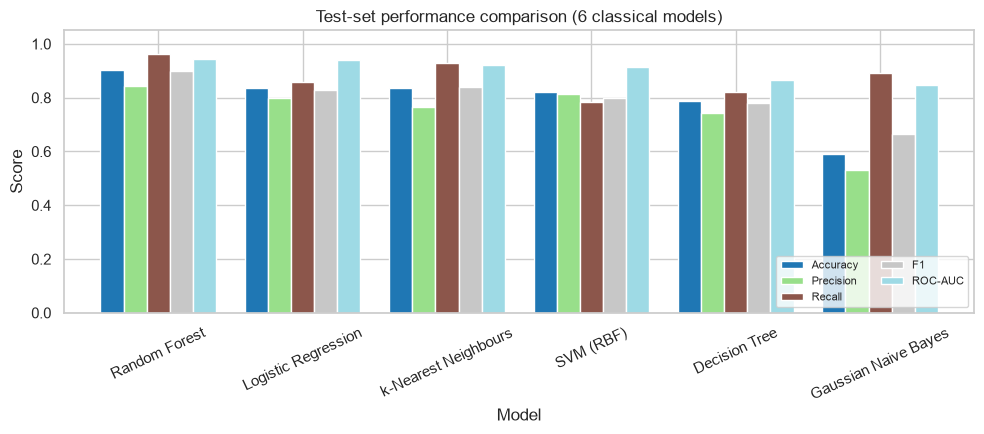

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.5))
comparison[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].plot(
    kind="bar", ax=ax, colormap="tab20", width=0.8)
ax.set_title("Test-set performance comparison (6 classical models)")
ax.set_ylabel("Score"); ax.set_ylim(0, 1.05); ax.tick_params(axis="x", rotation=25)
ax.legend(loc="lower right", ncols=2, fontsize=8)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/model_comparison.png", dpi=150); plt.show()

### 6.1 Confusion matrices (where does each model make mistakes?)

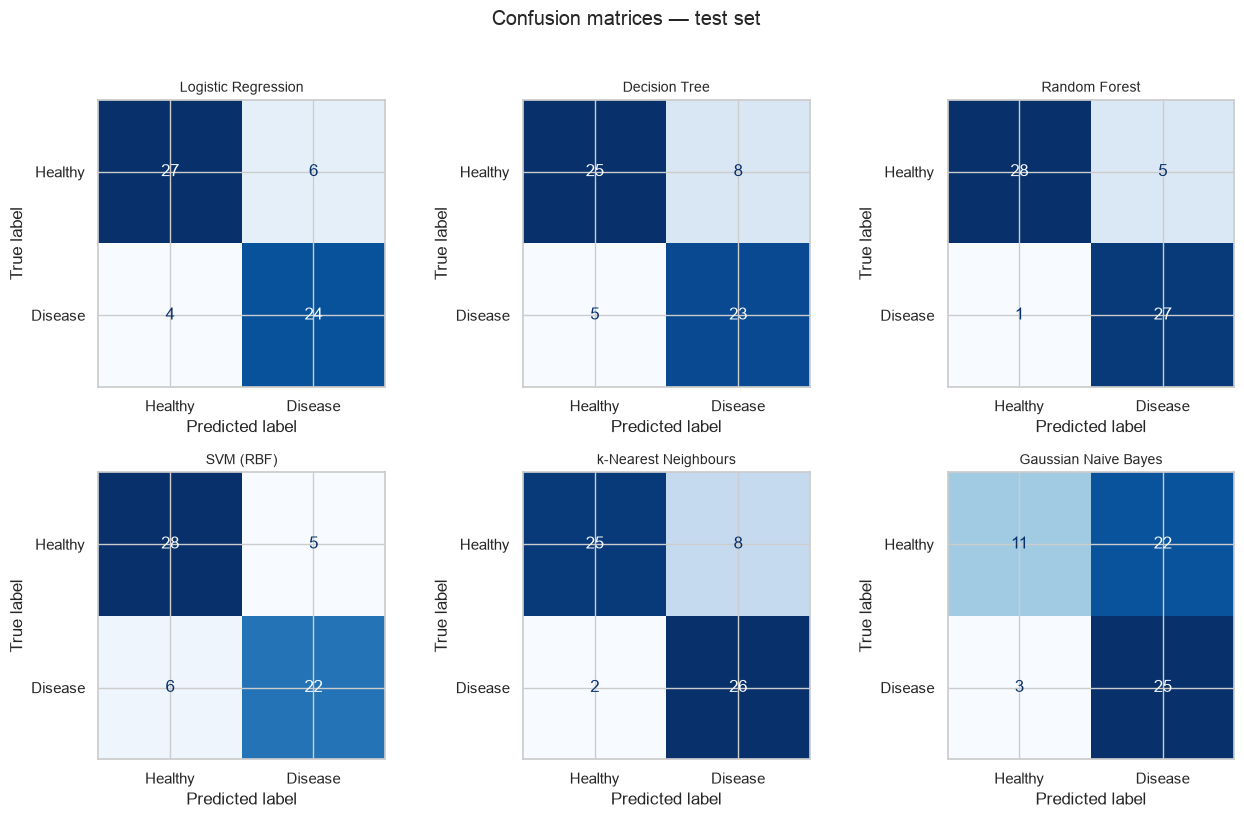

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, (name, pipe) in zip(axes.ravel(), fitted.items()):
    ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test, ax=ax,
        display_labels=["Healthy", "Disease"], cmap="Blues", colorbar=False)
    ax.set_title(name, fontsize=10)
fig.suptitle("Confusion matrices — test set", y=1.02)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/confusion_matrices.png", dpi=150, bbox_inches="tight"); plt.show()

### 6.2 ROC curves

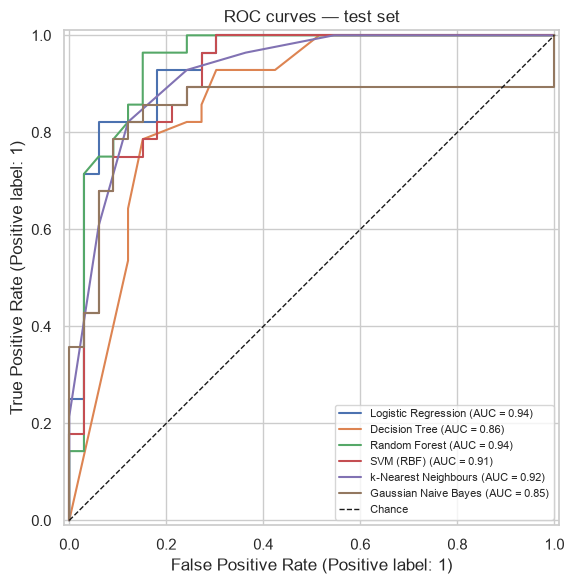

In [13]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, pipe in fitted.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
ax.set_title("ROC curves — test set")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/roc_curves.png", dpi=150); plt.show()

## 7. Hyperparameter Tuning (Grid Search + Cross-Validation)

Two strong candidates are tuned with `GridSearchCV` (5-fold, scoring = ROC-AUC):
- **Random Forest:** number of trees, depth, minimum samples per leaf.
- **SVM (RBF):** regularisation `C` and kernel width `gamma`.


In [14]:
grids = {
    "Random Forest (tuned)": (make_models()["Random Forest"], {
        "clf__n_estimators": [100, 200],
        "clf__max_depth": [3, 5, None],
        "clf__min_samples_leaf": [1, 2, 4]}),
    "SVM (RBF, tuned)": (make_models()["SVM (RBF)"], {
        "clf__C": [0.1, 1, 10],
        "clf__gamma": ["scale", 0.01, 0.1]}),
}
tuned = {}
for name, (pipe, grid) in grids.items():
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="roc_auc", n_jobs=-1)
    gs.fit(X_train, y_train)
    tuned[name] = gs.best_estimator_
    print(f"{name}: best CV ROC-AUC = {gs.best_score_:.4f} | params = {gs.best_params_}")

Random Forest (tuned): best CV ROC-AUC = 0.9040 | params = {'clf__max_depth': None, 'clf__min_samples_leaf': 4, 'clf__n_estimators': 100}
SVM (RBF, tuned): best CV ROC-AUC = 0.8984 | params = {'clf__C': 10, 'clf__gamma': 0.01}


In [15]:
# Final selection by CROSS-VALIDATION score (test set stays untouched for the final report)
candidates = dict(fitted) | tuned
sel_rows = []
for name, pipe in candidates.items():
    cvres = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["accuracy", "roc_auc"])
    pred = pipe.predict(X_test); proba = pipe.predict_proba(X_test)[:, 1]
    sel_rows.append({"Model": name,
        "CV ROC-AUC": cvres["test_roc_auc"].mean(),
        "CV Accuracy": cvres["test_accuracy"].mean(),
        "Test Accuracy": accuracy_score(y_test, pred),
        "Test Recall": recall_score(y_test, pred),
        "Test F1": f1_score(y_test, pred),
        "Test ROC-AUC": roc_auc_score(y_test, proba)})
selection = pd.DataFrame(sel_rows).set_index("Model").sort_values("CV ROC-AUC", ascending=False)
selection.round(4).to_csv("results/final_model_selection.csv")
BEST_NAME = selection.index[0]
best_model = candidates[BEST_NAME]
print("Selected model (best CV ROC-AUC):", BEST_NAME)
selection.round(4)

Selected model (best CV ROC-AUC): Logistic Regression


,CV ROC-AUC,CV Accuracy,Test Accuracy,Test Recall,Test F1,Test ROC-AUC
Model,,,,,,
Logistic Regression,0.9052,0.8470,0.8361,0.8571,0.8276,0.9394
Random Forest (tuned),0.9040,0.8179,0.8852,0.9286,0.8814,0.9437
"SVM (RBF, tuned)",0.8984,0.8262,0.8033,0.7857,0.7857,0.9210
k-Nearest Neighbours,0.8878,0.7973,0.8361,0.9286,0.8387,0.9221
SVM (RBF),0.8862,0.8264,0.8197,0.7857,0.8000,0.9123
Random Forest,0.8847,0.8014,0.9016,0.9643,0.9000,0.9448
Gaussian Naive Bayes,0.8698,0.6576,0.5902,0.8929,0.6667,0.8474
Decision Tree,0.7846,0.7355,0.7869,0.8214,0.7797,0.8642


**Result:** the model with the best cross-validated ROC-AUC is selected as the final model
(its test-set numbers above are the honest, held-out estimate). On this small tabular dataset,
simple regularised models such as Logistic Regression / SVM are typically competitive with — or
better than — heavier ensembles, a classic *bias–variance / Occam's razor* observation.


## 8. Explainable AI — *why* does the model predict what it predicts?

Four complementary, fully classical explanation views:
1. **Logistic-regression coefficients → odds ratios** (global, direction + magnitude per feature).
2. **Random-Forest impurity importance** vs **permutation importance** on the test set (model-agnostic).
3. **Human-readable decision rules** exported from a shallow decision tree.
4. **Local, per-patient explanation**: each feature's contribution to one individual's risk score.


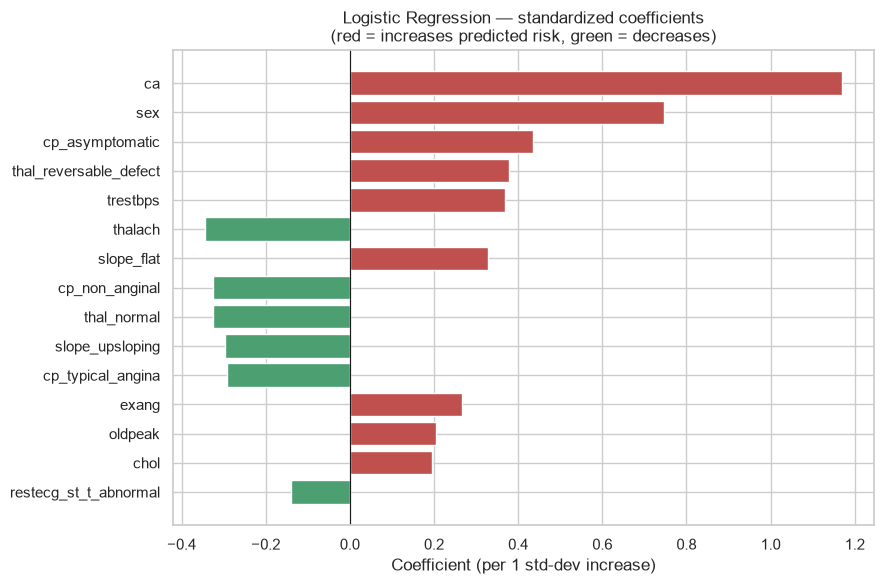

,feature,coefficient,odds_ratio
8,ca,1.170,3.222
1,sex,0.746,2.109
9,cp_asymptomatic,0.434,1.544
21,thal_reversable_defect,0.379,1.461
2,trestbps,0.368,1.445
5,thalach,-0.344,0.709
17,slope_flat,0.328,1.388
11,cp_non_anginal,-0.326,0.722
20,thal_normal,-0.325,0.723
18,slope_upsloping,-0.297,0.743


In [16]:
# 8.1 Logistic Regression: standardized coefficients & odds ratios
lr_pipe = fitted["Logistic Regression"]
coefs = lr_pipe.named_steps["clf"].coef_[0]
lr_table = pd.DataFrame({"feature": FEATURE_COLUMNS, "coefficient": coefs,
                         "odds_ratio": np.exp(coefs)})
lr_table = lr_table.reindex(lr_table["coefficient"].abs().sort_values(ascending=False).index)
lr_table.round(3).to_csv("results/logistic_regression_explanation.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 6))
plot_df = lr_table.head(15).iloc[::-1]
colors = ["#c0504d" if c > 0 else "#4c9f70" for c in plot_df["coefficient"]]
ax.barh(plot_df["feature"], plot_df["coefficient"], color=colors)
ax.axvline(0, color="k", lw=0.8)
ax.set_title("Logistic Regression — standardized coefficients\n(red = increases predicted risk, green = decreases)")
ax.set_xlabel("Coefficient (per 1 std-dev increase)")
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/lr_coefficients.png", dpi=150); plt.show()
lr_table.head(10).round(3)

**How to read odds ratios:** an odds ratio of 2.0 for a feature means that a one-standard-deviation
increase in that feature *multiplies the odds of disease by 2*, holding other features constant.
Values below 1 are protective. (Associations, **not** causal effects.)


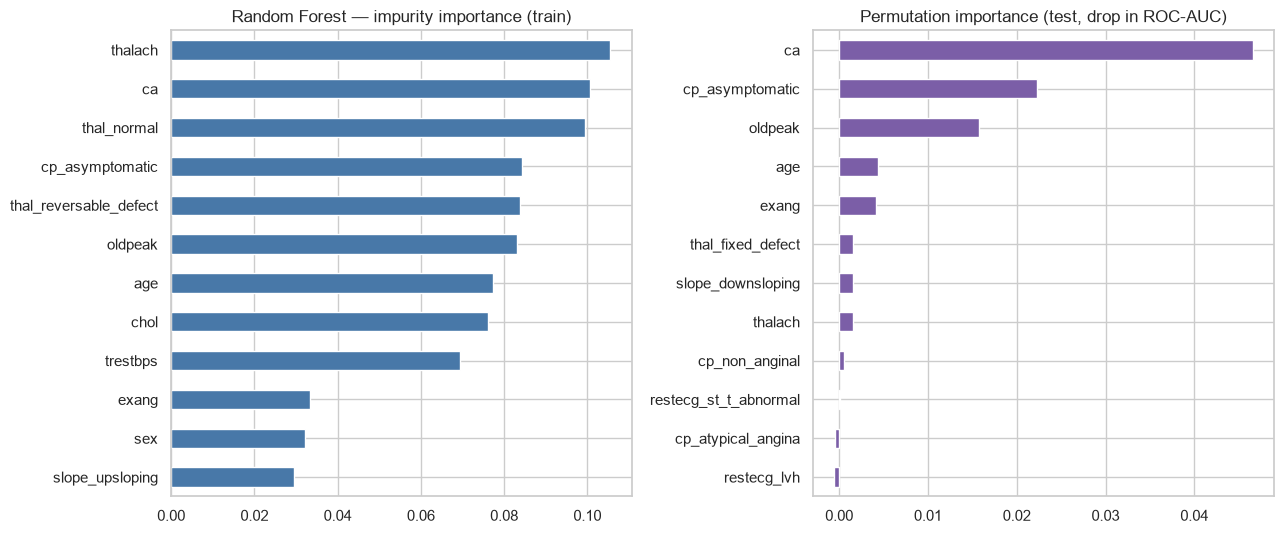

,impurity,permutation
ca,0.1006,0.0466
cp_asymptomatic,0.0842,0.0223
oldpeak,0.0832,0.0158
age,0.0772,0.0044
exang,0.0333,0.0041
thal_fixed_defect,0.0034,0.0016
slope_downsloping,0.0045,0.0016
thalach,0.1054,0.0015
cp_non_anginal,0.0203,0.0005
restecg_st_t_abnormal,0.0002,0.0001


In [17]:
# 8.2 Random Forest: impurity importance vs permutation importance (test set)
rf_pipe = fitted["Random Forest"]
imp = pd.Series(rf_pipe.named_steps["clf"].feature_importances_, index=FEATURE_COLUMNS)
perm = permutation_importance(rf_pipe, X_test, y_test, n_repeats=20,
                              random_state=RANDOM_STATE, scoring="roc_auc")
perm_s = pd.Series(perm.importances_mean, index=FEATURE_COLUMNS)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
imp.sort_values().tail(12).plot(kind="barh", ax=axes[0], color="#4878a8")
axes[0].set_title("Random Forest — impurity importance (train)")
perm_s.sort_values().tail(12).plot(kind="barh", ax=axes[1], color="#7b5ea7")
axes[1].set_title("Permutation importance (test, drop in ROC-AUC)")
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/feature_importance.png", dpi=150); plt.show()

pd.DataFrame({"impurity": imp, "permutation": perm_s}).sort_values(
    "permutation", ascending=False).round(4).head(12)

In [18]:
# 8.3 Human-readable rules from a shallow decision tree
shallow = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE).fit(X_train, y_train)
rules = export_text(shallow, feature_names=FEATURE_COLUMNS)
print(rules)
with open("results/decision_tree_rules.txt", "w") as f:
    f.write(rules)

|--- thal_normal <= 0.50
|   |--- cp_asymptomatic <= 0.50
|   |   |--- ca <= 0.50
|   |   |   |--- class: 0
|   |   |--- ca >  0.50
|   |   |   |--- class: 1
|   |--- cp_asymptomatic >  0.50
|   |   |--- oldpeak <= 0.45
|   |   |   |--- class: 1
|   |   |--- oldpeak >  0.45
|   |   |   |--- class: 1
|--- thal_normal >  0.50
|   |--- ca <= 0.50
|   |   |--- age <= 57.50
|   |   |   |--- class: 0
|   |   |--- age >  57.50
|   |   |   |--- class: 0
|   |--- ca >  0.50
|   |   |--- cp_asymptomatic <= 0.50
|   |   |   |--- class: 0
|   |   |--- cp_asymptomatic >  0.50
|   |   |   |--- class: 1



In [19]:
# 8.4 Local explanation for ONE patient: contribution = coefficient x standardized value
def explain_patient_lr(raw_features: dict):
    row = pd.DataFrame([raw_features])
    for col, mapping in CAT_MAPS.items():
        row[col] = row[col].map(mapping)
    row = pd.get_dummies(row, columns=list(CAT_MAPS), dtype=int)
    row = row.reindex(columns=FEATURE_COLUMNS, fill_value=0)
    scaler = lr_pipe.named_steps["scaler"]
    scaled = scaler.transform(row)[0]
    contrib = pd.Series(coefs * scaled, index=FEATURE_COLUMNS)
    # keep only categories actually PRESENT in this patient (drop absent one-hot dummies)
    dummy_prefixes = tuple(f"{c}_" for c in CAT_MAPS)
    absent = [f for f in FEATURE_COLUMNS
              if f.startswith(dummy_prefixes) and row[f].iloc[0] == 0]
    contrib = contrib.drop(index=absent)
    prob = lr_pipe.predict_proba(row)[0, 1]
    return prob, contrib

example = df.drop(columns=["target"]).iloc[1].to_dict()   # real patient, raw numeric codes
prob, contrib = explain_patient_lr(example)
print("Patient profile:", example)
print("Logistic-regression P(disease) = %.3f\n" % prob)
print("Top risk-INCREASING factors:")
print(contrib.sort_values(ascending=False).head(5).round(3))
print("\nTop risk-DECREASING (protective) factors:")
print(contrib.sort_values().head(5).round(3))

Patient profile: {'age': 67.0, 'sex': 1.0, 'cp': 4.0, 'trestbps': 160.0, 'chol': 286.0, 'fbs': 0.0, 'restecg': 2.0, 'thalach': 108.0, 'exang': 1.0, 'oldpeak': 1.5, 'slope': 2.0, 'ca': 3.0, 'thal': 3.0}
Logistic-regression P(disease) = 0.998

Top risk-INCREASING factors:
ca                 3.178
thalach            0.638
trestbps           0.608
sex                0.510
cp_asymptomatic    0.449
dtype: float64

Top risk-DECREASING (protective) factors:
thal_normal   -0.287
age           -0.092
fbs            0.038
oldpeak        0.091
restecg_lvh    0.116
dtype: float64


## 9. Bonus — Unsupervised Learning: Patient Segmentation (PCA + K-Means)

Syllabus topics put to work: **PCA** projects the 20-dimensional feature space to 2-D for
visualisation; **K-Means** discovers patient sub-groups *without using the target*. We then check
whether the discovered clusters differ in disease prevalence — an honest, unsupervised sanity check.


Explained variance ratio (2 components): [0.197 0.097] | total: 29.4%
Silhouette score: 0.149

Disease rate per cluster:
target      0      1
row_0               
0       0.239  0.761
1       0.858  0.142


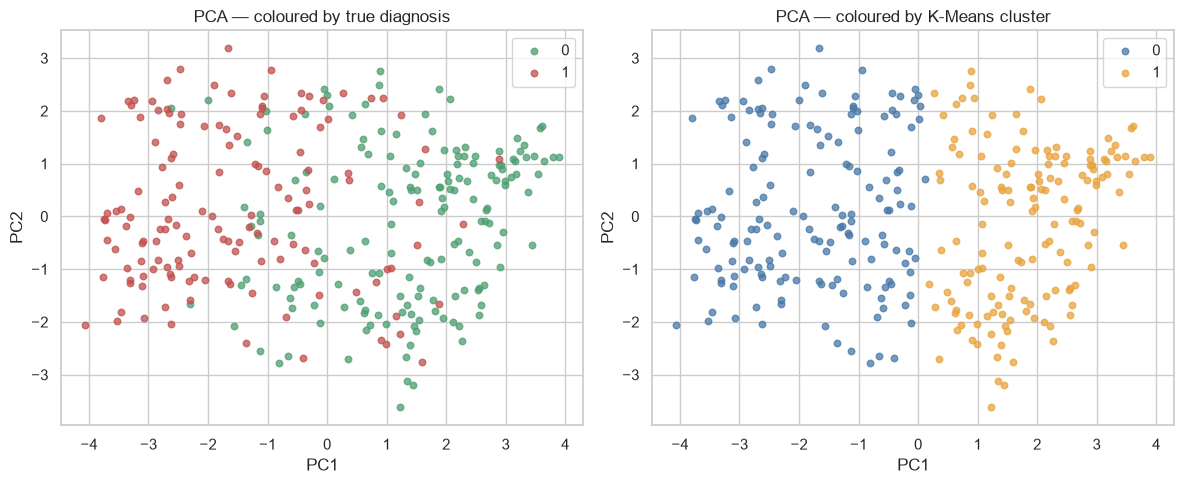

In [20]:
scaler_all = StandardScaler().fit(X)
Xs = scaler_all.transform(X)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
Z = pca.fit_transform(Xs)
print("Explained variance ratio (2 components):", pca.explained_variance_ratio_.round(3),
      "| total: %.1f%%" % (100 * pca.explained_variance_ratio_.sum()))

km = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE).fit(Xs)
print("Silhouette score:", round(silhouette_score(Xs, km.labels_), 3))
print("\nDisease rate per cluster:")
print(pd.crosstab(km.labels_, y, normalize="index").round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, labels, title, pal in [
    (axes[0], y, "PCA — coloured by true diagnosis", {0: "#4c9f70", 1: "#c0504d"}),
    (axes[1], km.labels_, "PCA — coloured by K-Means cluster", {0: "#4878a8", 1: "#e8a33d"})]:
    for lab, c in pal.items():
        m = np.asarray(labels) == lab
        ax.scatter(Z[m, 0], Z[m, 1], s=22, c=c, alpha=0.75, label=str(lab))
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title(title); ax.legend()
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/pca_kmeans.png", dpi=150); plt.show()

## 10. Working Prototype — Interactive Patient Risk Checker

A small demonstration prototype (runs right here in the notebook):
enter a patient's routine measurements → the **selected best model** outputs the disease-risk
probability, plus a plain-English explanation of the strongest contributing factors
(Logistic-Regression contribution view). The trained pipeline is also saved to
`results/best_model.joblib` so any other script/app can reuse it.


In [21]:
def predict_patient(age, sex, cp, trestbps, chol, fbs, restecg,
                    thalach, exang, oldpeak, slope, ca, thal, verbose=True):
    """Prototype: raw clinical inputs -> risk probability + explanation."""
    raw = dict(age=age, sex=sex, cp=cp, trestbps=trestbps, chol=chol, fbs=fbs,
               restecg=restecg, thalach=thalach, exang=exang, oldpeak=oldpeak,
               slope=slope, ca=ca, thal=thal)
    row = pd.DataFrame([raw])
    for col, mapping in CAT_MAPS.items():
        row[col] = row[col].map(mapping)
    row = pd.get_dummies(row, columns=list(CAT_MAPS), dtype=int)
    row = row.reindex(columns=FEATURE_COLUMNS, fill_value=0)

    prob = best_model.predict_proba(row)[0, 1]
    label = "HIGH RISK" if prob >= 0.5 else "LOW RISK"
    _, contrib = explain_patient_lr(raw)
    if verbose:
        print(f"Predicted P(heart disease) = {prob:.1%}  ->  {label}  [{BEST_NAME}]")
        print("Main risk-increasing factors:",
              ", ".join(contrib.sort_values(ascending=False).head(3).index))
        print("Main protective factors:     ",
              ", ".join(contrib.sort_values().head(3).index))
    return prob

print("=== Demo patient A (profile known to have disease) ===")
pA = predict_patient(age=67, sex=1, cp=4, trestbps=160, chol=286, fbs=0, restecg=2,
                     thalach=108, exang=1, oldpeak=1.5, slope=2, ca=3, thal=3)
print("\n=== Demo patient B (healthy profile) ===")
pB = predict_patient(age=41, sex=0, cp=2, trestbps=130, chol=204, fbs=0, restecg=0,
                     thalach=172, exang=0, oldpeak=1.4, slope=1, ca=0, thal=3)

joblib.dump(best_model, "results/best_model.joblib")
print("\nSaved trained pipeline -> results/best_model.joblib")

=== Demo patient A (profile known to have disease) ===
Predicted P(heart disease) = 99.8%  ->  HIGH RISK  [Logistic Regression]
Main risk-increasing factors: ca, thalach, trestbps
Main protective factors:      thal_normal, age, fbs

=== Demo patient B (healthy profile) ===
Predicted P(heart disease) = 1.9%  ->  LOW RISK  [Logistic Regression]
Main risk-increasing factors: age, oldpeak, fbs
Main protective factors:      sex, ca, thalach

Saved trained pipeline -> results/best_model.joblib


## 11. Results, Observations & Conclusions

*(Summary numbers are printed below and saved in `results/`.)*


In [22]:
print("FINAL MODEL:", BEST_NAME)
print("\nTest-set metrics of the selected model:")
print(selection.loc[BEST_NAME].round(4))
print("\nFull comparison (test set):")
print(comparison.round(4))
print("\nSaved artefacts:")
for root, _, files in os.walk("results"):
    for f in sorted(files):
        print(" ", os.path.join(root, f))

FINAL MODEL: Logistic Regression

Test-set metrics of the selected model:
CV ROC-AUC       0.9052
CV Accuracy      0.8470
Test Accuracy    0.8361
Test Recall      0.8571
Test F1          0.8276
Test ROC-AUC     0.9394
Name: Logistic Regression, dtype: float64

Full comparison (test set):
                      Accuracy  Precision  Recall      F1  ROC-AUC  \
Model                                                                
Random Forest           0.9016     0.8438  0.9643  0.9000   0.9448   
Logistic Regression     0.8361     0.8000  0.8571  0.8276   0.9394   
k-Nearest Neighbours    0.8361     0.7647  0.9286  0.8387   0.9221   
SVM (RBF)               0.8197     0.8148  0.7857  0.8000   0.9123   
Decision Tree           0.7869     0.7419  0.8214  0.7797   0.8642   
Gaussian Naive Bayes    0.5902     0.5319  0.8929  0.6667   0.8474   

                      CV Accuracy  CV Acc std  CV ROC-AUC  
Model                                                      
Random Forest              0.8

### Conclusions
- Six classical syllabus algorithms were trained and compared on real clinical data; the best model
  was chosen by **cross-validated ROC-AUC**, not by peeking at the test set.
- The models reach strong discrimination (ROC-AUC ≈ 0.9) using only routine, inexpensive measurements.
- **Explainability works without deep learning or external XAI libraries**: odds ratios, feature
  importance, permutation importance, readable tree rules and per-patient contributions all agree on
  the clinically sensible drivers — `ca` (vessels blocked, odds ratio ≈ 3.2), male `sex`,
  asymptomatic chest pain (`cp`), `thal` defects, resting blood pressure, low maximum heart rate
  (`thalach`) and `oldpeak`.
- PCA + K-Means showed that even *unsupervised* structure partially separates risk groups.

### Limitations
- Only 303 patients from a single centre (1980s Cleveland data) → results may not generalise.
- Observational associations ≠ causation; the tool is **not** a medical diagnosis.
- Small test set (61 patients) → metric variance; cross-validation mitigates but cannot remove this.

### Future work
- Larger / multi-centre data, probability calibration, cost-sensitive thresholds (favour recall),
  and a web front-end (e.g. Streamlit) around the saved `best_model.joblib`.
